# Dữ liệu và tiền xử lý PCAP

**CIC-IDS2017** cung cấp các phiên mạng doanh nghiệp mô phỏng. **InSDN** bổ sung các phiên thu trong môi trường SDN. Việc gộp hai nguồn giúp mô hình học từ nhiều bối cảnh, đồng thời kết quả tách theo nguồn cho thấy độ ổn định khác nhau giữa hai môi trường.

Mỗi hàng sau trích xuất là một flow hai chiều IPv4 TCP/UDP. Phiên là một tệp capture hoặc cửa sổ thời gian được khai báo. Bộ dữ liệu của lượt cuối gồm 31 phiên từ hai nguồn. Cột IP, timestamp và mã phiên dùng để kiểm tra nguồn gốc, gán nhãn và tách tập. Model dùng 12 cột số trong bảng dưới.

[Kế hoạch phiên](../configs/pcap_sessions_20261112.json) · [Nguồn CIC-IDS2017](https://www.unb.ca/cic/datasets/ids-2017.html) · [Nguồn InSDN](https://doi.org/10.1109/ACCESS.2020.3022633)

In [1]:
from datetime import datetime
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "configs/pcap_sessions_20261112.json").is_file())
sys.path.insert(0, str(root / "src"))
prepared = root / "experiments/pcap-scapy-20261112-seed42"
original = root / "experiments/pcap-combined-refit-seed42"

import os
import numpy as np
from dataset import SOURCES, feature_hashes, numeric_features
from features import FEATURES
from pcap_experiments import prepare
from taxonomy import map_labels

plan_path = root / "configs/pcap_sessions_20261112.json"
plan = json.loads(plan_path.read_text(encoding="utf-8"))
REBUILD = False
REUSE_EXTRACTED = True
if REBUILD:
    prepared = root / "experiments" / f"pcap-prepared-{datetime.now():%Y%m%d-%H%M%S-%f}"
    notebook_dir = Path.cwd()
    try:
        os.chdir(root)
        prepare(plan_path, prepared, reuse_extracted=REUSE_EXTRACTED)
    finally:
        os.chdir(notebook_dir)
    print(f"Dữ liệu đã lưu tại {prepared}")

## 1. Kế hoạch và gán nhãn

Mỗi phiên khai báo nguồn, nhãn, tập, cửa sổ UTC khi cần và điều kiện lọc. Điều kiện endpoint, port, chiều và payload giúp loại lưu lượng lẫn trong capture. Phiên có CSV đối chứng yêu cầu bản ghi cùng chiều bao phủ khoảng thời gian của flow và mọi bản ghi chồng lấp đồng thuận về nhãn. Bảng audit cho thấy số flow trích được, số đạt bộ lọc và số được gán nhãn sau đối chiếu. Đặt `REBUILD=True` để thực thi lại trên dữ liệu thật. Đặt `REUSE_EXTRACTED=False` để đọc PCAP gốc. Dữ liệu và thư mục cache được khai báo bằng đường dẫn tương đối từ gốc repo.

In [2]:
audit = pd.read_csv(prepared / "label_audit.csv")
assert set(audit.session) == {case["id"] for case in plan}
display(audit.groupby("source").agg(sessions=("session", "size"),
         extracted=("extracted", "sum"), eligible=("eligible", "sum"), labeled=("labeled", "sum")))
session_table = audit.drop(columns="flows").merge(
    pd.DataFrame(plan).rename(columns={"id": "session"})[["session", "pcap", "reference"]],
    on="session", validate="one_to_one")
session_table["reference"] = session_table.reference.notna()
display(session_table[["source", "session", "split", "raw_label", "reference",
                       "extracted", "eligible", "labeled"]])

,sessions,extracted,eligible,labeled
source,,,,
cicids2017,15,225190,162063,162063
insdn,16,111120,110679,80618


,source,session,split,raw_label,reference,extracted,eligible,labeled
0,cicids2017,cic-normal-a,train,BENIGN,False,1206,1206,1206
1,cicids2017,cic-normal-b,train,BENIGN,False,9459,9459,9459
2,cicids2017,cic-normal-c,validation,BENIGN,False,6948,6948,6948
3,cicids2017,cic-normal-d,test,BENIGN,False,5630,5630,5630
4,cicids2017,cic-recon-sS,train,PortScan,False,44252,43647,43647
5,cicids2017,cic-recon-firewall,train,PortScan,False,2640,87,87
6,cicids2017,cic-recon-sT,validation,PortScan,False,70892,68428,68428
7,cicids2017,cic-recon-late,test,PortScan,False,11179,7015,7015
8,cicids2017,cic-dos-slowloris,train,DoS slowloris,False,9099,1951,1951
9,cicids2017,cic-dos-hulk,train,DoS Hulk,False,15124,12823,12823


## 2. Schema và chất lượng dữ liệu

`FlowTable` xác định chiều đi bằng gói đầu tiên. Thời lượng bằng chênh lệch timestamp giữa gói đầu và cuối tính bằng µs. Số byte lấy từ payload tầng vận chuyển theo chiều dài header để tránh phần đệm Ethernet. Bộ đếm cờ FIN/SYN/RST/PSH/ACK/URG mô tả cách mở, truyền và đóng TCP. Flow UDP có các cờ TCP bằng 0.

Bộ gom flow dùng idle 10 giây, max-age 60 giây và giới hạn 10.000 flow đang mở. Trong tập học, loại flow đóng do chạm giới hạn dung lượng, flow ra ngoài cửa sổ và feature âm, thiếu hoặc vô hạn. Các bước này giữ phép `log1p` ở tầng meta hợp lệ và giảm mẫu gán nhãn thiếu căn cứ.

In [3]:
meaning = ["Cổng đích của gói đầu", "Thời lượng (µs)", "Gói chiều đi", "Gói chiều về",
           "Byte payload chiều đi", "Byte payload chiều về"] + ["Số gói TCP có cờ " + flag
           for flag in ("FIN", "SYN", "RST", "PSH", "ACK", "URG")]
display(pd.DataFrame({"Đặc trưng": FEATURES, "Ý nghĩa": meaning}))

labeled = pd.concat([
    pd.read_csv(prepared / f"{source}-labeled.csv").assign(
        family=lambda frame: map_labels(frame.RawLabel, source))
    for source in SOURCES
], ignore_index=True)
x = numeric_features(labeled)
quality = pd.DataFrame({"Thiếu hoặc vô hạn": (~np.isfinite(x)).sum(),
                        "Âm": x.lt(0).sum(), "Min": x.min(),
                        "Trung vị": x.median(), "P95": x.quantile(.95), "Max": x.max()})
display(quality.round(2))
assert quality.iloc[:, :2].to_numpy().sum() == 0
display(labeled.groupby(["source_dataset", "RawLabel", "family"]).size().rename("Flow").to_frame())
display(labeled[["source_dataset", "session_id", "RawLabel", "family", *FEATURES]].head())

,Đặc trưng,Ý nghĩa
0,Destination Port,Cổng đích của gói đầu
1,Flow Duration,Thời lượng (µs)
2,Total Fwd Packets,Gói chiều đi
3,Total Backward Packets,Gói chiều về
4,Total Length of Fwd Packets,Byte payload chiều đi
5,Total Length of Bwd Packets,Byte payload chiều về
6,FIN Flag Count,Số gói TCP có cờ FIN
7,SYN Flag Count,Số gói TCP có cờ SYN
8,RST Flag Count,Số gói TCP có cờ RST
9,PSH Flag Count,Số gói TCP có cờ PSH


,Thiếu hoặc vô hạn,Âm,Min,Trung vị,P95,Max
Destination Port,0,0,1.0,1296.00,32783.00,65531.00
Flow Duration,0,0,0.0,73.91,1291019.92,59998077.15
Total Fwd Packets,0,0,1.0,1.00,8.00,4999.00
Total Backward Packets,0,0,0.0,1.00,7.00,4391.00
Total Length of Fwd Packets,0,0,0.0,0.00,406.00,16835000.00
Total Length of Bwd Packets,0,0,0.0,0.00,11595.00,14937000.00
FIN Flag Count,0,0,0.0,0.00,2.00,60.00
SYN Flag Count,0,0,0.0,1.00,2.00,9.00
RST Flag Count,0,0,0.0,1.00,2.00,17.00
PSH Flag Count,0,0,0.0,0.00,4.00,4991.00


Flow
source_dataset RawLabel                 family             
cicids2017     BENIGN                   BENIGN        23243
               DoS GoldenEye            DOS            3379
               DoS Hulk                 DOS           12823
               DoS Slowhttptest         DOS             933
               DoS slowloris            DOS            1951
               FTP-Patator              BRUTE_FORCE     316
               PortScan                 RECON        119177
               SSH-Patator              BRUTE_FORCE     230
               Web Attack - Brute Force BRUTE_FORCE      11
insdn          BFA                      BRUTE_FORCE     703
               DoS                      DOS            9150
               Normal                   BENIGN         9748
               Probe                    RECON         61017

,source_dataset,session_id,RawLabel,family,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count
0,cicids2017,cic-normal-a,BENIGN,BENIGN,389,165.939331,2,2,188,278,0,0,0,0,0,0
1,cicids2017,cic-normal-a,BENIGN,BENIGN,53,242.948532,2,2,170,270,0,0,0,0,0,0
2,cicids2017,cic-normal-a,BENIGN,BENIGN,53,294.923782,2,2,108,208,0,0,0,0,0,0
3,cicids2017,cic-normal-a,BENIGN,BENIGN,389,146.150589,2,2,188,278,0,0,0,0,0,0
4,cicids2017,cic-normal-a,BENIGN,BENIGN,389,285346.031189,23,16,5970,1000,2,4,2,18,37,0


## 3. Phân bố và tương quan

Biểu đồ theo nhãn cho thấy RECON áp đảo trước khi lấy mẫu. Bảng thống kê và histogram giúp nhìn thang đo khác nhau giữa số byte, thời lượng và cờ TCP. `log1p` được dùng ở đây để quan sát cả giá trị 0 lẫn phần đuôi dài. Tương quan Spearman cho thấy đặc trưng nào đồng biến theo thứ hạng. Phép đo này phục vụ EDA và tập fit vẫn sử dụng đủ 12 đặc trưng.

source_dataset,cicids2017,insdn,percent
family,,,
BENIGN,23243,9748,13.59
BRUTE_FORCE,557,703,0.52
DOS,19086,9150,11.64
RECON,119177,61017,74.25


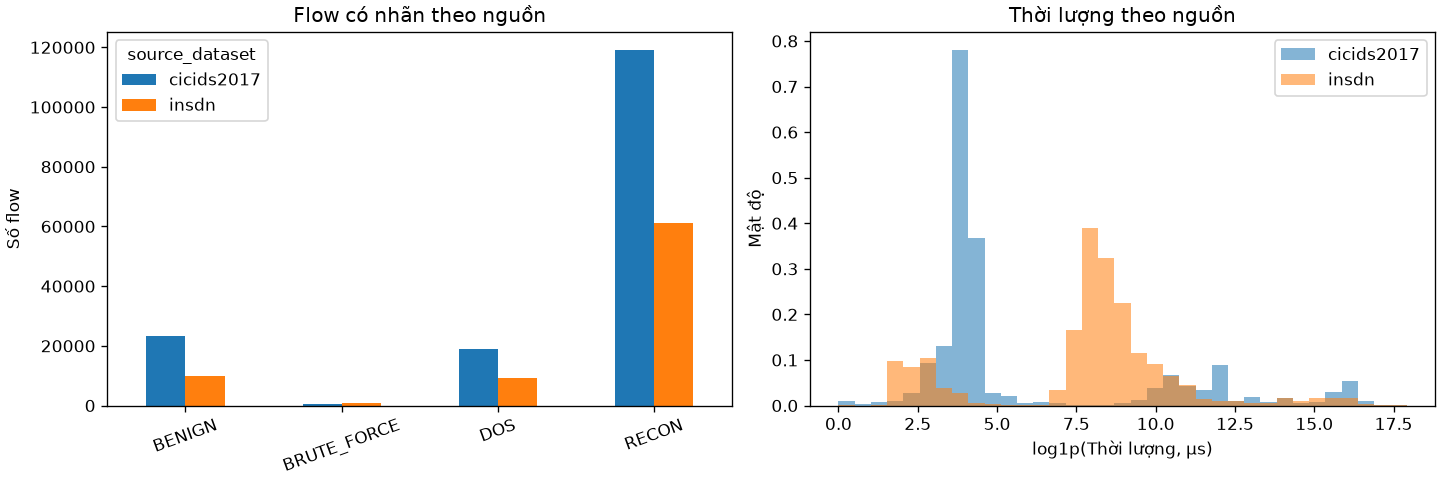

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count
Destination Port,1.00,-0.51,-0.62,-0.60,-0.67,-0.64,-0.44,-0.16,0.34,-0.52,-0.40,0.06
Flow Duration,-0.51,1.00,0.69,0.67,0.66,0.66,0.59,0.13,-0.27,0.60,0.54,0.07
Total Fwd Packets,-0.62,0.69,1.00,0.96,0.91,0.92,0.76,0.53,-0.22,0.85,0.70,-0.07
Total Backward Packets,-0.60,0.67,0.96,1.00,0.88,0.93,0.76,0.53,-0.16,0.83,0.68,-0.07
Total Length of Fwd Packets,-0.67,0.66,0.91,0.88,1.00,0.92,0.65,0.37,-0.30,0.84,0.61,-0.08
Total Length of Bwd Packets,-0.64,0.66,0.92,0.93,0.92,1.00,0.68,0.43,-0.21,0.78,0.55,-0.07
FIN Flag Count,-0.44,0.59,0.76,0.76,0.65,0.68,1.00,0.50,-0.02,0.82,0.71,0.22
SYN Flag Count,-0.16,0.13,0.53,0.53,0.37,0.43,0.50,1.00,0.26,0.53,0.57,-0.20
RST Flag Count,0.34,-0.27,-0.22,-0.16,-0.30,-0.21,-0.02,0.26,1.00,-0.12,-0.08,0.04
PSH Flag Count,-0.52,0.60,0.85,0.83,0.84,0.78,0.82,0.53,-0.12,1.00,0.84,0.17


In [4]:
from io import BytesIO
import matplotlib.pyplot as plt
from IPython.display import Image

by_class = pd.crosstab(labeled.family, labeled.source_dataset)
display(by_class.assign(percent=(100 * by_class.sum(axis=1) / len(labeled)).round(2)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
by_class.plot.bar(ax=axes[0], rot=20, ylabel="Số flow", xlabel="", title="Flow có nhãn theo nguồn")
for source in SOURCES:
    axes[1].hist(np.log1p(x.loc[labeled.source_dataset.eq(source), "Flow Duration"]),
                 bins=35, density=True, alpha=.55, label=source)
axes[1].set(xlabel="log1p(Thời lượng, µs)", ylabel="Mật độ", title="Thời lượng theo nguồn")
axes[1].legend()
with BytesIO() as image:
    fig.savefig(image, format="png", dpi=120)
    display(Image(data=image.getvalue()))
plt.close(fig)
display(x.corr(method="spearman").round(2))

## 4. Tách tập và chống trùng

Tách theo phiên để flow liên quan trong cùng capture hoặc cửa sổ không bị rải sang tập khác. Giữ test, loại vector trùng test khỏi validation và loại vector trùng cả hai khỏi train. Train còn loại vector có nhãn mâu thuẫn và khử trùng trước khi chia ngân sách tối đa 2.000 flow theo từng cặp nguồn–lớp giữa các phiên train. Validation và test giữ phân bố sau các bước lọc tương ứng. Notebook huấn luyện thực hiện giới hạn theo phiên khi gộp train và validation.

In [5]:
splits = {part: pd.concat([pd.read_csv(prepared / "splits" / source / f"{part}.csv")
                          for source in SOURCES], ignore_index=True)
          for part in ("train", "validation", "test")}
table = pd.concat(splits.values(), ignore_index=True)
display(pd.crosstab([table.source_dataset, table.split], table.Label, margins=True))
hashes = {part: set(feature_hashes(frame)) for part, frame in splits.items()}
sessions = {part: set(frame.session_id) for part, frame in splits.items()}
for left, right in (("train", "validation"), ("train", "test"), ("validation", "test")):
    assert not hashes[left] & hashes[right]
    assert not sessions[left] & sessions[right]
print("Tách biệt giữa các tập theo session_id và vector đặc trưng.")

Label                      BENIGN  BRUTE_FORCE    DOS   RECON     All
source_dataset split                                                 
cicids2017     test          5630           11   3379    7015   16035
               train         2000          546   2000    1072    5618
               validation    6840            0    933   62365   70138
insdn          test          3693          144   6507      96   10440
               train         1903          557   1246    2000    5706
               validation    3261            1     49   36065   39376
All                         23327         1259  14114  108613  147313

Tách biệt giữa các tập theo session_id và vector đặc trưng.
